**Real-world questions:** Which interpolation method performs best on held-out
readings? Do complete years exhibit similar **seasonal shapes**?

**Deliverables:** (1) a holdout RMSE comparison table, (2) an interpolation
comparison chart, (3) a year × month heatmap and cluster plot, and (4) an
explanation of what the clusters do **not** prove.

**Caution:** Randomly hiding individual known readings evaluates interpolation
under *that masking pattern*. It is not a guarantee for long missing gaps.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Works when you launch Jupyter from the repository root or notebooks/ folder.
def data_path(filename):
    # Search for the data folder from the current
    # working directory up to the repository root.
    for folder in [Path.cwd(), *Path.cwd().parents]:
        candidate = folder / "data" / filename

        if candidate.is_file():
            return candidate

    raise FileNotFoundError(
        f"Cannot find {filename}. "
        f"Current directory: {Path.cwd()}"
    )

plt.rcParams.update({'figure.figsize': (11, 4.5), 'axes.grid': True,
                     'grid.alpha': 0.25, 'figure.dpi': 105})

from scipy.interpolate import PchipInterpolator, CubicSpline
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram

In [3]:
df = (pd.read_csv(data_path('MaunaLoa_CO2_Full.csv'), parse_dates=['date'])
        .set_index('date').sort_index())
assert df.index.is_unique and df.index.is_monotonic_increasing
assert len(df) == 2284, 'Please use the supplied full historical dataset.'
assert int(df['co2_ppm'].isna().sum()) == 59
print('Rows:', len(df), '| Missing:', df['co2_ppm'].isna().sum())
print('Period:', df.index.min().date(), 'to', df.index.max().date())
display(df.head())

Rows: 2284 | Missing: 59
Period: 1958-03-29 to 2001-12-29


,co2_ppm
date,
1958-03-29,316.1
1958-04-05,317.3
1958-04-12,317.6
1958-04-19,317.5
1958-04-26,316.4


## Step 1 — Hold out known observations for honest validation
    We intentionally hide **150 observed values** using a reproducible random seed.
    The original 59 missing values remain missing in the training data.
    Do not use the held-out values when fitting an interpolator.

In [4]:
rng = np.random.default_rng(7)
observed_positions = np.flatnonzero(df.co2_ppm.notna().to_numpy())
# Avoid edge points so this task evaluates interpolation, not extrapolation.
interior_positions = observed_positions[(observed_positions > 2) &
                                        (observed_positions < len(df)-3)]
holdout_positions = rng.choice(interior_positions, size=150, replace=False)
holdout_dates = df.index[holdout_positions]
actual = df.loc[holdout_dates, 'co2_ppm'].to_numpy()

train = df.co2_ppm.copy()
train.loc[holdout_dates] = np.nan
assert train.isna().sum() == 59 + 150
print('Original missing:', df.co2_ppm.isna().sum(),
      '| Artificially hidden:', len(holdout_dates),
      '| Training missing:', train.isna().sum())

Original missing: 59 | Artificially hidden: 150 | Training missing: 209


## Step 2 — Fit linear, PCHIP, and cubic-spline interpolation
    SciPy interpolation methods require **sorted numeric x-coordinates**.
    We use elapsed days; the 150 hidden values are excluded from training.

In [5]:
train_observed = train.dropna()
x_train = (train_observed.index - df.index[0]).days.to_numpy(dtype=float)
y_train = train_observed.to_numpy(dtype=float)
x_test = (holdout_dates - df.index[0]).days.to_numpy(dtype=float)

predictions = {
    'Linear': np.interp(x_test, x_train, y_train),
    'PCHIP': PchipInterpolator(x_train, y_train, extrapolate=False)(x_test),
    'Cubic spline': CubicSpline(x_train, y_train, extrapolate=False)(x_test),
}
comparison = pd.DataFrame([
    {'method': name, 'RMSE_ppm': np.sqrt(np.mean((actual - pred)**2)),
     'MAE_ppm': np.mean(np.abs(actual - pred))}
    for name, pred in predictions.items()
]).sort_values('RMSE_ppm')
display(comparison.round(3))
print('Lowest holdout RMSE:', comparison.iloc[0]['method'])

,method,RMSE_ppm,MAE_ppm
0,Linear,0.345,0.254
1,PCHIP,0.357,0.268
2,Cubic spline,0.397,0.307


Lowest holdout RMSE: Linear


## Step 3 — Inspect a local time window visually
    A smooth curve is not automatically a more accurate reconstruction.

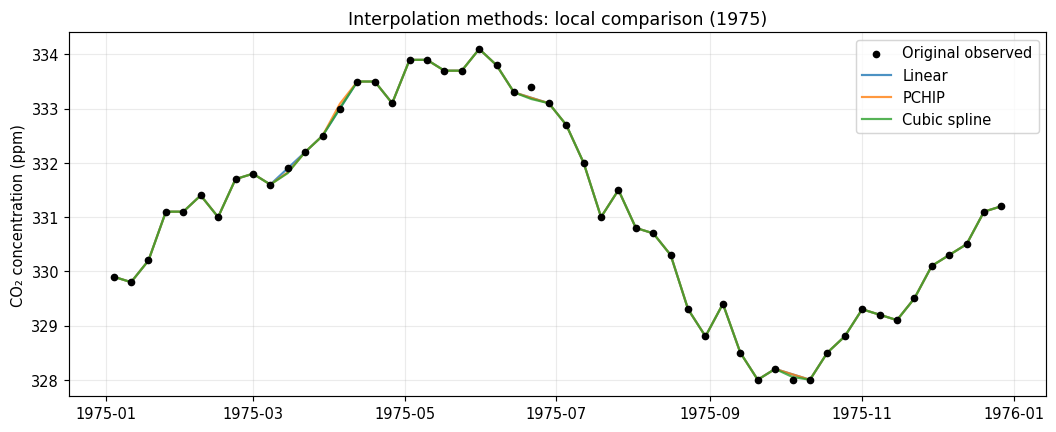

In [6]:
window = slice('1975-01-01', '1976-01-01')
dates = df.loc[window].index
x_window = (dates - df.index[0]).days.to_numpy(dtype=float)
plt.figure(figsize=(12, 4.5))
plt.scatter(df.loc[window].index, df.loc[window, 'co2_ppm'],
            s=18, color='black', label='Original observed', zorder=5)
plt.plot(dates, np.interp(x_window, x_train, y_train),
         label='Linear', alpha=0.8)
plt.plot(dates, PchipInterpolator(x_train, y_train, extrapolate=False)(x_window),
         label='PCHIP', alpha=0.8)
plt.plot(dates, CubicSpline(x_train, y_train, extrapolate=False)(x_window),
         label='Cubic spline', alpha=0.8)
plt.title('Interpolation methods: local comparison (1975)')
plt.ylabel('CO₂ concentration (ppm)')
plt.legend()
plt.show()

## Step 4 — Build a full year × month table
    We now use the entire time series. To compare seasonal **shape**, first fill
    the original missing readings, calculate monthly averages, and centre each
    complete year by subtracting that year's mean.

Complete years × months: (43, 12)


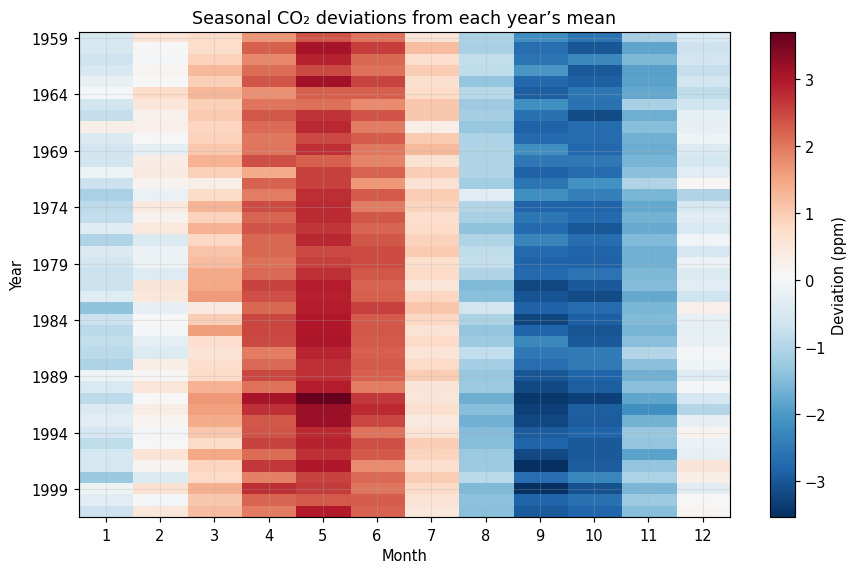

In [7]:
filled = df.co2_ppm.interpolate(method='time', limit_area='inside')
monthly = filled.resample('MS').mean()
monthly_table = (monthly.to_frame('co2_ppm')
                 .assign(year=lambda d: d.index.year,
                         month=lambda d: d.index.month)
                 .pivot(index='year', columns='month', values='co2_ppm')
                 .dropna())
seasonal = monthly_table.sub(monthly_table.mean(axis=1), axis=0)
assert seasonal.shape == (43, 12)
print('Complete years × months:', seasonal.shape)

fig, ax = plt.subplots(figsize=(10, 6))
im = ax.imshow(seasonal.to_numpy(), aspect='auto', cmap='RdBu_r')
ax.set(title='Seasonal CO₂ deviations from each year’s mean',
       xlabel='Month', ylabel='Year')
ax.set_xticks(range(12), labels=range(1, 13))
ax.set_yticks(range(0, len(seasonal), 5),
              labels=seasonal.index[::5].tolist())
fig.colorbar(im, ax=ax, label='Deviation (ppm)')
plt.show()

## Step 5 — Cluster 43 seasonal profiles with SciPy
    Ward hierarchical clustering groups similar **12-month patterns**.
    Cluster labels are arbitrary identifiers; they do not explain causes.

Cluster sizes:


,years
cluster,
1,9
2,12
3,22


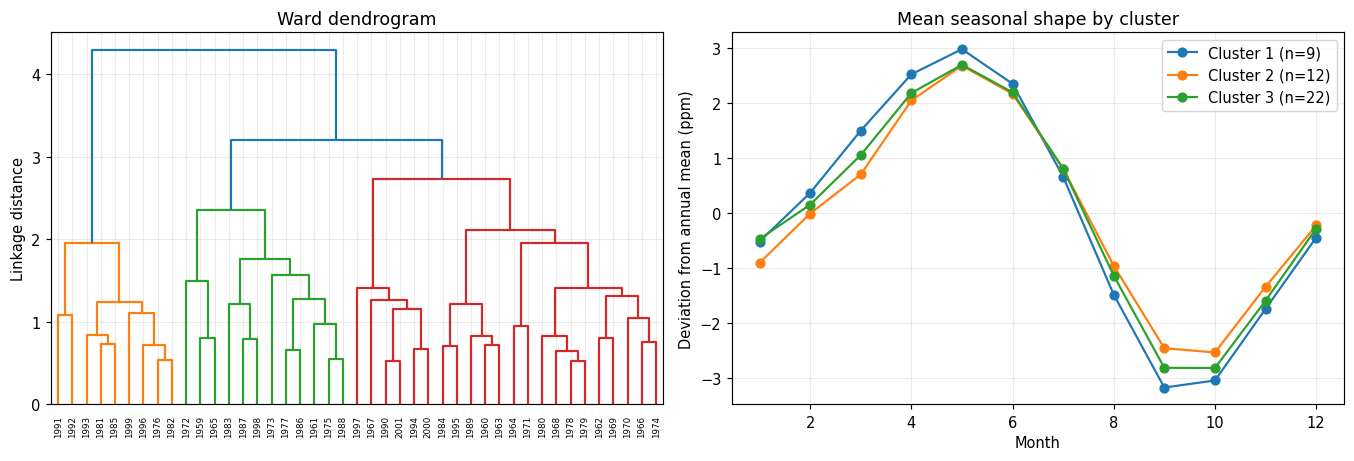

In [8]:
Z = linkage(seasonal.to_numpy(), method='ward', metric='euclidean')
cluster_labels = fcluster(Z, t=3, criterion='maxclust')
cluster_table = pd.DataFrame({'year': seasonal.index,
                              'cluster': cluster_labels}).set_index('year')
print('Cluster sizes:')
display(cluster_table['cluster'].value_counts().sort_index().rename('years').to_frame())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
dendrogram(Z, labels=seasonal.index.astype(str).tolist(),
           leaf_rotation=90, leaf_font_size=6, ax=axes[0])
axes[0].set(title='Ward dendrogram', ylabel='Linkage distance')
for group in sorted(np.unique(cluster_labels)):
    mean_profile = seasonal.loc[cluster_table.cluster == group].mean(axis=0)
    axes[1].plot(range(1, 13), mean_profile.to_numpy(), marker='o',
                 label=f'Cluster {group} (n={(cluster_labels == group).sum()})')
axes[1].set(title='Mean seasonal shape by cluster',
            xlabel='Month', ylabel='Deviation from annual mean (ppm)')
axes[1].legend()
plt.tight_layout()
plt.show()

## Your investigation — evidence and interpretation
    **A.** Which method has the lowest holdout RMSE? Would you automatically
    choose it for a **multi-week gap**? Explain why or why not.

    **B.** Find a period containing original missing values, plot the reconstructed
    values against the observed points, and discuss potential uncertainty.

    **C.** Compare the sizes and average shapes of the three clusters. Do not
    claim that clustering identifies a causal mechanism.

    **Extension:** Change the number of clusters to **2** and **4**. Does the
    interpretation remain stable? Try validating a **contiguous block** of
    known observations rather than randomly isolated points.

In [ ]:
# YOUR TURN
# 1. Identify a multi-week gap in df.co2_ppm.
# 2. Change the number of clusters (fcluster with t=2 or t=4).
# 3. Write down two similarities and one limitation.

### Reflection checklist
    - [ ] I kept test readings out of the interpolation training set.
    - [ ] I compared errors numerically, not only by smoothness.
    - [ ] I used all **43 complete years** for seasonal clustering.
    - [ ] I described clusters as similarity groups, not proven causes.